In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
DATA_PATH = Path("../data/raw/customer_churn.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


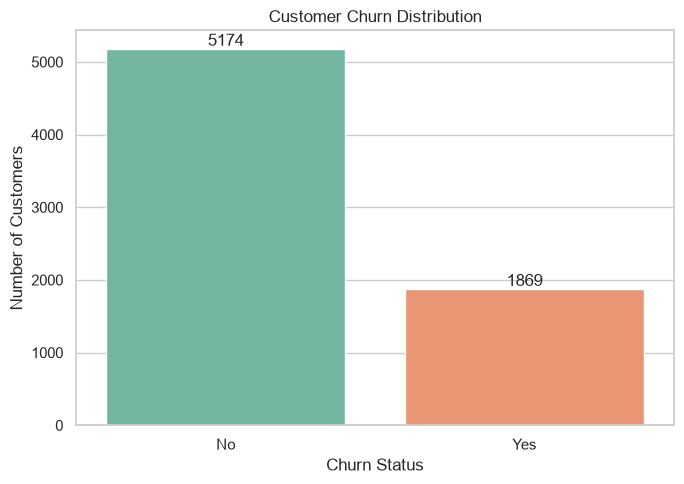

In [3]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [5]:
# Calculating the average tenure for each class
df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
Churn,,,,
No,5174,37.57,38.0,24.11
Yes,1869,17.98,10.0,19.53


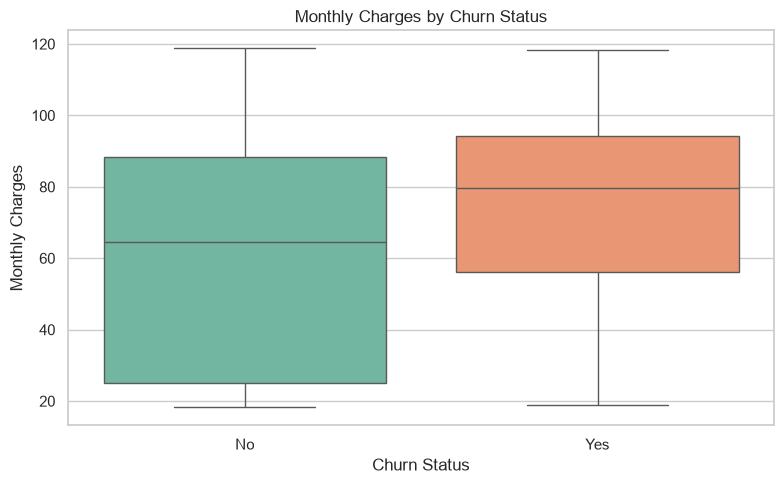

In [6]:
#Analyzing the monthly charges

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    order=["No", "Yes"],
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [7]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

,mean,median,std,min,max
Churn,,,,,
No,61.27,64.43,31.09,18.25,118.75
Yes,74.44,79.65,24.67,18.85,118.35


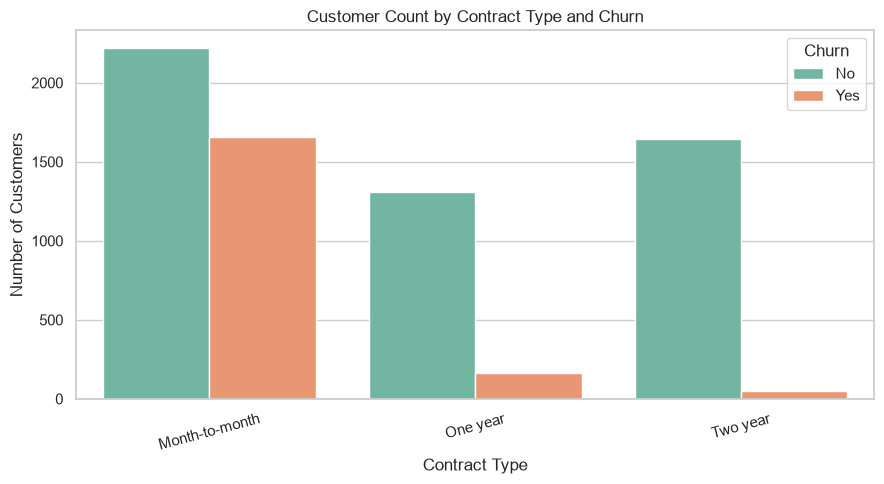

In [8]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    order=["Month-to-month", "One year", "Two year"],
    palette="Set2"
)

plt.title("Customer Count by Contract Type and Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [9]:
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn_rate.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


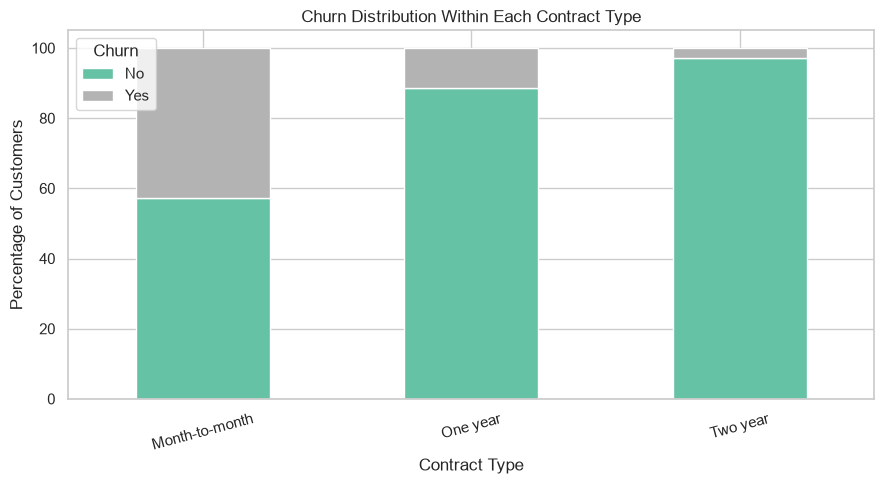

In [10]:
contract_churn_rate.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)

plt.title("Churn Distribution Within Each Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=15)
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

# Exploratory Data Analysis (EDA) Findings
## Customer Churn Classification

### 1. Dataset Overview

The dataset contains customer information from a telecommunications company. The objective is to identify patterns associated with customer churn and use these insights to develop a classification model.

- **Total records:** 7,043
- **Total columns:** 21
- **Target variable:** `Churn`
- **Problem type:** Binary Classification
- **Target classes:** `Yes` (customer churned) and `No` (customer stayed)

The dataset includes customer demographics, service subscriptions, contract information, payment methods, tenure, and billing details.

### 2. Target Variable Distribution

The target variable represents whether a customer has left the company.

| Churn Status | Number of Customers | Percentage |
|---|---:|---:|
| No | 5,174 | 73.46% |
| Yes | 1,869 | 26.54% |
| **Total** | **7,043** | **100%** |

**Observations:**

- Approximately 73.46% of customers stayed with the company.
- Approximately 26.54% of customers churned.
- The dataset has an imbalanced target distribution because the number of customers who stayed is considerably greater than the number who churned.

**Implications for modelling:**

Accuracy alone will not be sufficient to evaluate the classification models. A model that predicts every customer as a non-churner would achieve approximately 73.46% accuracy but fail to identify any customers who churned.

Therefore, precision, recall, F1-score, ROC-AUC, and the confusion matrix will be considered alongside accuracy during model evaluation.

### 3. Customer Tenure Analysis

Tenure represents the number of months a customer has remained with the company.

The following descriptive statistics were obtained:

| Churn Status | Customer Count | Mean Tenure (Months) | Median Tenure (Months) | Standard Deviation |
|---|---:|---:|---:|---:|
| No | 5,174 | 37.57 | 38.0 | 24.11 |
| Yes | 1,869 | 18.00 | 10.0 | 19.53 |

**Observations:**

- Customers who stayed had an average tenure of approximately 37.57 months.
- Customers who churned had an average tenure of approximately 18 months.
- The median tenure of churned customers was only 10 months, compared with 38 months for customers who stayed.
- The difference between the mean and median tenure among churned customers suggests that their tenure distribution is not symmetric.

**Key insight:**

Customer churn is associated with shorter tenure in this dataset. Customers who leave tend to have shorter relationships with the company than those who remain.

**Implications for modelling:**

Tenure is likely to be an informative predictive feature. We should examine its relationship with other variables and retain it as a candidate feature during model training.

This association does not establish that shorter tenure causes churn.

### 4. Monthly Charges Analysis

Monthly charges represent the recurring amount billed to customers.

The box plot compares monthly charges between customers who stayed and those who churned.

**Observations:**

- The median monthly charges appear higher among customers who churned.
- Customers who stayed exhibit a wider spread across the lower monthly-charge range.
- The distributions overlap, indicating that monthly charges alone may not reliably distinguish churners from non-churners.
- Both groups contain customers with relatively high monthly charges.

**Key insight:**

Monthly charges may contain useful information for predicting customer churn. However, their predictive value should be evaluated alongside other features, particularly contract type, tenure, and service subscriptions.

**Implications for modelling:**

`MonthlyCharges` will be retained as a numerical feature. We will investigate its statistical relationship with churn and assess its contribution during model evaluation.

### 5. Contract Type Analysis

The dataset contains three contract categories:

- Month-to-month
- One year
- Two year

The initial count plot shows the number of customers in each contract category, separated by churn status.

However, comparing raw counts alone can be misleading because the number of customers differs across contract categories. Therefore, churn percentages were calculated within each category.

| Contract Type | Stayed (%) | Churned (%) |
|---|---:|---:|
| Month-to-month | 57.29% | 42.71% |
| One year | 88.73% | 11.27% |
| Two year | 97.17% | 2.83% |

**Observations:**

- Month-to-month contracts have the highest churn rate, at 42.71%.
- One-year contracts have a substantially lower churn rate of 11.27%.
- Two-year contracts have the lowest churn rate, at 2.83%.
- The churn rate decreases considerably as the contract duration increases.

**Key insight:**

Contract type shows a strong association with customer churn in this dataset. Customers on month-to-month contracts are substantially more likely to churn than customers on longer-term contracts.

**Implications for modelling:**

`Contract` will be retained as an important categorical feature. We will encode it appropriately during preprocessing and evaluate its contribution to the classification models.

These findings describe associations in the observed data and do not establish that longer contracts independently cause lower churn.

### 6. Preliminary Feature-Level Insights

Based on the analyses completed so far, the following features appear promising:

| Feature | Type | Preliminary Finding | Modelling Decision |
|---|---|---|---|
| `tenure` | Numerical | Churned customers tend to have shorter tenure. | Retain |
| `MonthlyCharges` | Numerical | Churned customers appear to have higher median monthly charges. | Retain |
| `Contract` | Categorical | Month-to-month contracts have substantially higher churn rates. | Retain |
| `customerID` | Identifier | Identifies customers but has no obvious direct predictive meaning. | Exclude from model features |
| `Churn` | Target | Represents the outcome to predict. | Use as the target variable |

These are preliminary findings. Further analysis is needed to examine service subscriptions, payment methods, demographics, and relationships between the features.

### 7. Data Quality Considerations

The initial data inspection identified an issue with `TotalCharges`.

- The column is initially stored as a string rather than a numerical data type.
- Eleven records contain blank `TotalCharges` values.
- All eleven affected customers have zero tenure.
- These records have valid `MonthlyCharges` values and a churn status of `No`.

**Planned preprocessing:**

1. Convert `TotalCharges` into a numerical column.
2. Investigate the blank entries and document the handling strategy.
3. Retain the affected records where possible rather than deleting them unnecessarily.
4. Exclude `customerID` from the model features.
5. Encode categorical variables using an appropriate strategy.
6. Scale numerical features for algorithms that are sensitive to feature magnitude.

All preprocessing transformations will be fitted on the training data only to prevent data leakage.

### 8. Implications for Classification Model Selection

Four classification algorithms will be evaluated:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree
4. Support Vector Machine (SVM)

The dataset contains both numerical and categorical features. Consequently, preprocessing must be consistent and appropriate for each algorithm.

**Planned approach:**

- Use a stratified train-test split to preserve the target-class proportions.
- Apply suitable categorical encoding and missing-value handling.
- Scale numerical features for Logistic Regression, KNN, and SVM.
- Evaluate a Decision Tree using the same training and test split, without requiring feature scaling.
- Use cross-validation and hyperparameter tuning to improve promising models.
- Compare the models using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.
- Select the final model based on its evaluation results and the practical objective of identifying customers at risk of churning.

Recall will be particularly important because failing to identify a customer who churns may represent a missed retention opportunity. However, precision must also be considered because incorrectly flagging customers can lead to unnecessary retention efforts.

The final model will be selected based on measured performance rather than assuming that one algorithm is inherently superior.

### 9. EDA Conclusion

The exploratory analysis has revealed three notable patterns:

1. The target variable is imbalanced, with approximately 26.54% of customers having churned.
2. Customers who churned generally have shorter tenure than customers who stayed.
3. Contract type is strongly associated with churn, with month-to-month contracts exhibiting substantially higher churn rates than longer-term contracts.

Monthly charges also appear to differ between the two churn groups and warrant further investigation.

These findings provide an initial understanding of the dataset and guide our feature preparation and model evaluation strategy.

The next stage is to complete the remaining exploratory analysis, implement a reproducible preprocessing pipeline, and compare the four classification algorithms to identify the most suitable model for deployment through Streamlit.